# Esquema do RAG

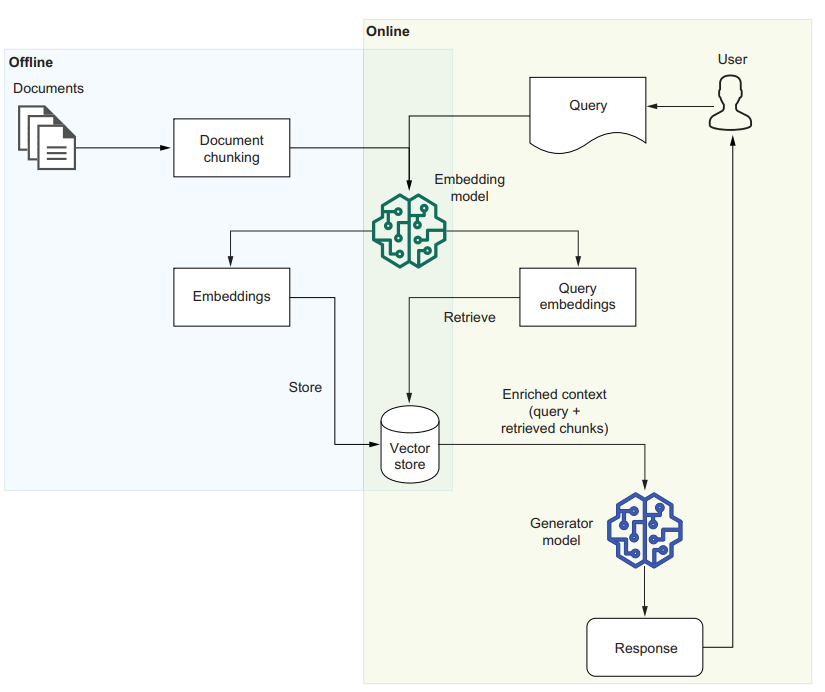

# Instalando e importando bilbiotecas.

In [ ]:
!pip install PyMuPDF

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 MB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 36.5 MB/s eta 0:00:00


In [ ]:
import os
import re
import fitz
import requests
import pandas as pd
from tqdm.auto import tqdm
from spacy.lang.pt import Portuguese

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


# Pré-tratamento do texto

In [ ]:
pdf_path = "36135-577-29231-1-10-20250716.pdf"

if not os.path.exists(pdf_path):
  print("File doesn't exist, downloading it...")

  url = "https://sol.sbc.org.br/index.php/sbcup/article/download/36135/35922/"

  filename = pdf_path

  response = requests.get(url)

  if response.status_code == 200:
      with open(filename, "wb") as file:
          file.write(response.content)
      print(f"The file has been downloaded and saved as {filename}")
  else:
      print(f"Failed to download the file. Status code: {response.status_code}")
else:
  print(f"File {pdf_path} exists.")

File doesn't exist, downloading it...
The file has been downloaded and saved as 36135-577-29231-1-10-20250716.pdf


Função que utiliza o PyMuPDF para extrair o texto puro do PDF e também conseguir algumas estatísticas sobre ele.

In [ ]:
def text_formatter(text):
    cleaned_text = text.replace("\n", " ").strip()
    return cleaned_text

def open_and_read_pdf(pdf_path):
    """
    Opens a PDF file, reads its text content page by page, and collects statistics.

    Parameters:
        pdf_path (str): The file path to the PDF document to be opened and read.

    Returns:
        list[dict]: A list of dictionaries, each containing the page number
        (adjusted), character count, word count, sentence count, token count, and the extracted text
        for each page.
    """
    doc = fitz.open(pdf_path)
    pages_and_texts = []
    for page_number, page in tqdm(enumerate(doc)):
        text = page.get_text()
        text = text_formatter(text)
        pages_and_texts.append({"page_number": page_number + 1,
                                "page_char_count": len(text),
                                "page_word_count": len(text.split(" ")),
                                "page_sentence_count_raw": len(text.split(". ")),
                                "page_token_count": len(text) / 4,
                                "text": text})
    return pages_and_texts

In [ ]:
pages_and_texts = open_and_read_pdf(pdf_path=pdf_path)
pages_and_texts[:1]

0it [00:00, ?it/s]

[{'page_number': 1,
  'page_char_count': 3183,
  'page_word_count': 462,
  'page_sentence_count_raw': 24,
  'page_token_count': 795.75,
  'text': 'Monitoramento Inteligente de Tempo Real para Tráfego Urbano em Cidades Brasileiras Carlos Loureiro, Elloá B. Guedes, Carlos M. S. Figueiredo 1Grupo de Pesquisa em Sistemas Inteligentes Universidade do Estado do Amazonas Av. Darcy Vargas, 1200 – Manaus – Amazonas {cenlf.eng22, ebgcosta, cfigueiredo}@uea.edu.br Abstract. To contribute to real-time urban traffic monitoring in Brazilian cities, this work presents an intelligent solution utilizing images from urban surveillance came- ras to train models for vehicle counting and classification. The YOLOv11 Medium model achieved an experimental mAP of 0.7372 at 94 FPS and was deployed in an in- teractive dashboard. This work also proposes a benchmark for the vehicle detection task and contributes to adaptive and responsive strategies for smart urban mobility in Brazilian cities. Resumo. Visando con

Dividindo o texto do documento em frases utilizando SpaCy.

In [ ]:
nlp = Portuguese()

nlp.add_pipe("sentencizer")

In [ ]:
for item in tqdm(pages_and_texts):
    item["sentences"] = list(nlp(item["text"]).sents)

    item["sentences"] = [str(sentence) for sentence in item["sentences"]]

    item["page_sentence_count_spacy"] = len(item["sentences"])

  0%|          | 0/10 [00:00<?, ?it/s]

Agrupando frases em pedaços de 10 frases.

In [ ]:
num_sentence_chunk_size = 10

def split_list(input_list, slice_size):

    return [input_list[i:i + slice_size] for i in range(0, len(input_list), slice_size)]

In [ ]:
for item in tqdm(pages_and_texts):
    item["sentence_chunks"] = split_list(input_list=item["sentences"], slice_size=num_sentence_chunk_size)
    item["num_chunks"] = len(item["sentence_chunks"])

  0%|          | 0/10 [00:00<?, ?it/s]

Criando um dicionário de pedaços, colocando também suas estatísticas.

In [ ]:
pages_and_chunks = []
for item in tqdm(pages_and_texts):
    for sentence_chunk in item["sentence_chunks"]:
        chunk_dict = {}
        chunk_dict["page_number"] = item["page_number"]

        joined_sentence_chunk = "".join(sentence_chunk).replace("  ", " ").strip()
        joined_sentence_chunk = re.sub(r'\.([A-Z])', r'. \1', joined_sentence_chunk)
        chunk_dict["sentence_chunk"] = joined_sentence_chunk

        chunk_dict["chunk_char_count"] = len(joined_sentence_chunk)
        chunk_dict["chunk_word_count"] = len([word for word in joined_sentence_chunk.split(" ")])
        chunk_dict["chunk_token_count"] = len(joined_sentence_chunk) / 4 # 1 token = ~4 characters

        pages_and_chunks.append(chunk_dict)

  0%|          | 0/10 [00:00<?, ?it/s]

Quantidade de pedaços e criando dataframe de estatísticas dos pedaços.

In [ ]:
len(pages_and_chunks)

27

In [ ]:
df = pd.DataFrame(pages_and_chunks)
df.describe().round(2)

,page_number,chunk_char_count,chunk_word_count,chunk_token_count
count,27.00,27.00,27.00,27.00
mean,6.19,1055.85,159.07,263.96
std,3.19,536.11,82.58,134.03
min,1.00,172.00,21.00,43.00
25%,3.50,568.50,80.50,142.12
50%,6.00,1085.00,170.00,271.25
75%,9.00,1494.50,220.50,373.62
max,10.00,2028.00,328.00,507.00


Filtrando pedaços que possuem menos de 30 tokens, pois provavelmente contém informação descartável.

In [ ]:
min_token_length = 30
subset_df = df[df["chunk_token_count"] <= min_token_length]

for row in subset_df.sample(min(5, len(subset_df)), replace=True).iterrows():
    print(f'Chunk token count: {row[1]["chunk_token_count"]} | Text: {row[1]["sentence_chunk"]}')

In [ ]:
pages_and_chunks_over_min_token_len = df[df["chunk_token_count"] > min_token_length].to_dict(orient="records")
pages_and_chunks_over_min_token_len[:1]

[{'page_number': 1,
  'sentence_chunk': 'Monitoramento Inteligente de Tempo Real para Tráfego Urbano em Cidades Brasileiras Carlos Loureiro, Elloá B. Guedes, Carlos M. S. Figueiredo 1Grupo de Pesquisa em Sistemas Inteligentes Universidade do Estado do Amazonas Av. Darcy Vargas, 1200 – Manaus – Amazonas {cenlf.eng22, ebgcosta, cfigueiredo}@uea.edu.br Abstract. To contribute to real-time urban traffic monitoring in Brazilian cities, this work presents an intelligent solution utilizing images from urban surveillance came- ras to train models for vehicle counting and classification. The YOLOv11 Medium model achieved an experimental mAP of 0.7372 at 94 FPS and was deployed in an in- teractive dashboard. This work also proposes a benchmark for the vehicle detection task and contributes to adaptive and responsive strategies for smart urban mobility in Brazilian cities. Resumo. Visando contribuir para o monitoramento em tempo real do tráfego urbano em cidades brasileiras, este trabalho apresen

Importando o modelo de embedding

In [ ]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(model_name_or_path="intfloat/multilingual-e5-base", device="cpu")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Criando os embeddings com o modelo.

In [ ]:
for item in tqdm(pages_and_chunks_over_min_token_len):
    item["embedding"] = embedding_model.encode(item["sentence_chunk"])

  0%|          | 0/27 [00:00<?, ?it/s]

Salvando os resultados em um arquivo .csv

In [ ]:
import numpy as np

text_chunks_and_embeddings_df = pd.DataFrame(pages_and_chunks_over_min_token_len)
text_chunks_and_embeddings_df['embedding_str'] = text_chunks_and_embeddings_df['embedding'].apply(
    lambda x: np.array2string(x, separator=',')[1:-1])
embeddings_df_save_path = "text_chunks_and_embeddings_df.csv"
text_chunks_and_embeddings_df.to_csv(embeddings_df_save_path, index=False)

# Adicionando o banco de dados vetorial (LanceDB)

Instalando, importando, criando e conectando a um banco vazio.

In [ ]:
!pip install lancedb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.2/75.2 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 406.8/406.8 kB 25.9 MB/s eta 0:00:00


In [ ]:
import lancedb

db = lancedb.connect("paperdb")

Carregando o arquivo gerado anteriormente e o exibindo.

In [ ]:
text_chunks_and_embedding_df_load = pd.read_csv(embeddings_df_save_path)
text_chunks_and_embedding_df_load['embedding_final'] = text_chunks_and_embedding_df_load['embedding_str'].apply(lambda x: np.fromstring(x, sep=','))
text_chunks_and_embedding_df_load.head()

,page_number,sentence_chunk,chunk_char_count,chunk_word_count,chunk_token_count,embedding,embedding_str,embedding_final
0,1,Monitoramento Inteligente de Tempo Real para T...,1633,241,408.25,[ 2.94311922e-02 3.45775411e-02 -2.67731515e-...,"2.94311922e-02, 3.45775411e-02,-2.67731515e-0...","[0.0294311922, 0.0345775411, -0.00267731515, 0..."
1,1,"2018], nos quais habitam 87,4 % da população b...",1546,218,386.50,[ 3.15483175e-02 4.39680554e-02 -5.82241314e-...,"3.15483175e-02, 4.39680554e-02,-5.82241314e-0...","[0.0315483175, 0.0439680554, -0.00582241314, 0..."
2,2,falhas em pavimentações asfálticas [Carvalho e...,1678,248,419.50,[ 3.06804143e-02 3.17909271e-02 -7.27176666e-...,"3.06804143e-02, 3.17909271e-02,-7.27176666e-0...","[0.0306804143, 0.0317909271, -0.00727176666, 0..."
3,2,Trabalhos Relacionados Para compreender de for...,1639,248,409.75,[ 2.35719755e-02 6.42774850e-02 1.09520322e-...,"2.35719755e-02, 6.42774850e-02, 1.09520322e-0...","[0.0235719755, 0.064277485, 0.00109520322, 0.0..."
4,2,"Considerada de baixo custo e não invasiva, a a...",541,82,135.25,[ 1.65031701e-02 4.04712446e-02 -6.98113395e-...,"1.65031701e-02, 4.04712446e-02,-6.98113395e-0...","[0.0165031701, 0.0404712446, -0.00698113395, 0..."


Preparando a coluna de embeddings e os outros dados para ingestão no banco de dados.

In [ ]:
final_data = []
for row in text_chunks_and_embedding_df_load.itertuples(index=False):
    temp = {}
    temp["page_number"] = row.page_number
    temp["chunk_char_count"] = row.chunk_char_count
    temp["chunk_word_count"] = row.chunk_word_count
    temp["chunk_token_count"] = row.chunk_token_count
    temp["sentence_chunk"] = row.sentence_chunk
    temp["embedding"] = np.array(row.embedding_final)
    final_data.append(temp)

Armazenando os embeddings e os dados em uma tabela no banco via Apache Arrow (PyArrow).

In [ ]:
import pyarrow as pa

In [ ]:
data_dict = {}
for key in final_data[0].keys():
    data_dict[key] = [d[key] for d in final_data]

In [ ]:
table = db.create_table(
    "paper_embeddings_table",
    data=pa.Table.from_pydict(data_dict),
    mode="overwrite",
    schema=pa.schema([
        ("page_number", pa.int64()),
        ("chunk_char_count", pa.int64()),
        ("chunk_word_count", pa.int64()),
        ("chunk_token_count", pa.float64()),
        ("sentence_chunk", pa.string()),
        ("embedding", pa.list_(pa.float32(), list_size=768)),
    ]),
)

Indexando a tabela no banco.

In [ ]:
db["paper_embeddings_table"].create_index(
    metric="cosine",
    vector_column_name="embedding",
    index_type="IVF_FLAT",
)

/tmp/ipykernel_1187/3320220380.py:1: DeprecationWarning: The create_index() API with metric/num_partitions parameters is deprecated and will be removed in a future version. Please migrate to the new unified API:
  # Old (deprecated):
  table.create_index('l2', vector_column_name='my_vector')
  # New (recommended):
  table.create_index('my_vector', config=IvfPq(distance_type='l2'))
  db["paper_embeddings_table"].create_index(


Criando uma consulta, depois convertendo-a.

In [ ]:
query = "transporte rodoviário"
query_embedding = embedding_model.encode(query, convert_to_tensor=False)

Fazendo uma consulta no banco vetorial.

In [ ]:
results = db["paper_embeddings_table"].search(
        query_embedding,
        vector_column_name="embedding"
    ).limit(3).to_list()

In [ ]:
print("Search results:")
for result in results:
    print(result['_distance'])
    print(result['sentence_chunk'])
    print(result['page_number'])
    print("")

Search results:
0.14535051584243774
IBGE (2022). Instituto Brasileiro de Geografia e Estatística – Censo Demográfico 2022. Dis- ponível em https://tinyurl.com/yc2vyj7d. Acesso: 03/mar/2025. Leal, D. M. (2023). Detecção e Rastreamento de Objetos em Vídeo via Rede Neural Convo- lucional (CNN). Instituto Federal do Espírito Santo. Curso de Engenharia de Controle e Automação (Trabalho de Conclusão de Curso). Moreira, M. A. L., Freitas Junior, M. d., and Toloi, R. C. (2018). O transporte rodoviário no Brasil e suas deficiências.
10

0.16553807258605957
Monitoramento Inteligente de Tempo Real para Tráfego Urbano em Cidades Brasileiras Carlos Loureiro, Elloá B. Guedes, Carlos M. S. Figueiredo 1Grupo de Pesquisa em Sistemas Inteligentes Universidade do Estado do Amazonas Av. Darcy Vargas, 1200 – Manaus – Amazonas {cenlf.eng22, ebgcosta, cfigueiredo}@uea.edu.br Abstract. To contribute to real-time urban traffic monitoring in Brazilian cities, this work presents an intelligent solution utilizing

# Geração

Instalando o pacote llama-cpp-python e baixando o modelo gerador.

In [ ]:
!pip install llama-cpp-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 MB 5.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.8 MB/s eta 0:00:00
  Created wheel for llama-cpp-python: filename=llama_cpp_python-0.3.36-py3-none-linux_x86_64.whl size=24338992 sha256=038bf30c829e8cf1cb638d167aa07d312dec55a5c201bc6af4dfcc69241df3a1
  Stored in directory: /root/.cache/pip/wheels/e5/bf/ad/f5f50f854633df40f54d89e4e5271e987476036203819f8b4c
Successfully built llama-cpp-python


In [ ]:
from llama_cpp import Llama

llm = Llama.from_pretrained(
    repo_id="unsloth/Llama-3.2-3B-Instruct-GGUF",
    filename="*Q4_K_M.gguf",
    verbose=False,
    n_ctx=4096
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


./Llama-3.2-3B-Instruct-Q4_K_M.gguf: reconstructing file:   0%|          |  0.00B / 2.02GB            

./Llama-3.2-3B-Instruct-Q4_K_M.gguf: downloading bytes:           |  0.00B            

Baixando o tokenizador associado ao modelo escolhido.

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("unsloth/Llama-3.2-3B-Instruct")

config.json:   0%|          | 0.00/890 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/3.83k [00:00<?, ?B/s]

Criando uma consulta e convertendo ela.

In [ ]:
query = "transporte rodoviário"
query_embedding = embedding_model.encode(query, convert_to_tensor=True)

Função que formata o prompt para o gerador, combinando a consulta, os pedaços de textos e um prompt base.

In [ ]:
def prompt_formatter(query,
                     context_items,
                     tokenizer):
    context = "- " + "\n- ".join([item["sentence_chunk"] for item in context_items])

    base_prompt = """Baseado nos seguintes contextos, por favor responda o pedido.
Responda sempre em português do Brasil e garanta que suas respostas são as mais claras possíveis.
\nUse os seguintes contextos para responder o pedido do usuário:
{context}
\nPassagens relevantes: <extraia passagens relevantes do contexto aqui>
Pedido do usuário: {query}
Resposta:"""

    base_prompt = base_prompt.format(context=context, query=query)

    dialogue_template = [
        {"role": "user",
        "content": base_prompt}
    ]

    prompt = tokenizer.apply_chat_template(conversation=dialogue_template,
                                          tokenize=False,
                                          add_generation_prompt=True)
    return prompt

Formatando a consulta para incluir a consulta do banco de dados.

In [ ]:
prompt_lancedb = prompt_formatter(query=query,
                          context_items=results[0:2],
                          tokenizer=tokenizer)
prompt_lancedb

'<|begin_of_text|><|start_header_id|>system<|end_header_id|>\n\nCutting Knowledge Date: December 2023\nToday Date: 20 Oct 2026\n\n<|eot_id|><|start_header_id|>user<|end_header_id|>\n\nBaseado nos seguintes contextos, por favor responda o pedido. \nResponda sempre em português do Brasil e garanta que suas respostas são as mais claras possíveis.\n\nUse os seguintes contextos para responder o pedido do usuário:\n- IBGE (2022). Instituto Brasileiro de Geografia e Estatística – Censo Demográfico 2022. Dis- ponível em https://tinyurl.com/yc2vyj7d. Acesso: 03/mar/2025. Leal, D. M. (2023). Detecção e Rastreamento de Objetos em Vídeo via Rede Neural Convo- lucional (CNN). Instituto Federal do Espírito Santo. Curso de Engenharia de Controle e Automação (Trabalho de Conclusão de Curso). Moreira, M. A. L., Freitas Junior, M. d., and Toloi, R. C. (2018). O transporte rodoviário no Brasil e suas deficiências.\n- Monitoramento Inteligente de Tempo Real para Tráfego Urbano em Cidades Brasileiras Carlo

Gerando e mostrando a resposta.

In [ ]:
output = llm(
      prompt_lancedb,
      max_tokens=None,
      stop=["Q:", "\n"],
      echo=True
)

/usr/local/lib/python3.13/dist-packages/llama_cpp/llama.py:1314: RuntimeWarning: Detected duplicate leading "<|begin_of_text|>" in prompt, this will likely reduce response quality, consider removing it...
  warnings.warn(


In [ ]:
output

{'id': 'cmpl-e57f3d25-31b0-47bd-8683-e208828c3389',
 'object': 'text_completion',
 'created': 1792521527,
 'model': '/root/.cache/huggingface/hub/models--unsloth--Llama-3.2-3B-Instruct-GGUF/snapshots/e7d0997e49c9cb00d88b4c1a6a16aa894b0bbc31/./Llama-3.2-3B-Instruct-Q4_K_M.gguf',
 'choices': [{'text': '<|begin_of_text|><|start_header_id|>system<|end_header_id|>\n\nCutting Knowledge Date: December 2023\nToday Date: 20 Oct 2026\n\n<|eot_id|><|start_header_id|>user<|end_header_id|>\n\nBaseado nos seguintes contextos, por favor responda o pedido. \nResponda sempre em português do Brasil e garanta que suas respostas são as mais claras possíveis.\n\nUse os seguintes contextos para responder o pedido do usuário:\n- IBGE (2022). Instituto Brasileiro de Geografia e Estatística – Censo Demográfico 2022. Dis- ponível em https://tinyurl.com/yc2vyj7d. Acesso: 03/mar/2025. Leal, D. M. (2023). Detecção e Rastreamento de Objetos em Vídeo via Rede Neural Convo- lucional (CNN). Instituto Federal do Espíri

In [ ]:
def extract_answer(llm_output):
    text_generated = llm_output['choices'][0]['text']
    marker = "<|start_header_id|>assistant<|end_header_id|>\n\n"
    answer = text_generated.split(marker)[-1].strip()
    return answer

final_answer = extract_answer(output)
print(final_answer)

Com base nos contextos fornecidos, podemos identificar que o transporte rodoviário é um tema importante no Brasil, com 65% das deslocações de carga e passegios realizadas por meio dessas vias, e que 78,1% das rodovias estão sob a responsabilidade dos municípios (Moreira et al., 2018).
